In [9]:
import numpy as np
import scipy.fft as sp_fft
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
from multiprocessing import Pool
from tqdm import tqdm
import pandas as pd
import joblib
import os
import datetime
import pickle

# load

In [34]:
BASE_DIR = '/home/invisibleam/amh_spectral/ml-fluidDynamics/float32/amh_128_results/amh_spatiotemporal_results_float32_400'

def _find_file(prefix, extension=None):
    if not os.path.isdir(BASE_DIR):
        return None
    candidates = [
        fn for fn in os.listdir(BASE_DIR)
        if fn.startswith(prefix) and (extension is None or fn.endswith(extension))
    ]
    if not candidates:
        return None
    return sorted(candidates)[0]

MODEL_FN = _find_file('model_', '.pth')
SCALER_FN = _find_file('scaler_', '.pkl')
HISTORY_FN = _find_file('history_', '.pkl')
RESULTS_FN = _find_file('results_df_', '.pkl')
DATASET_FN = _find_file('dataset_', '.npz')


def _load_pkl(path):
    if not os.path.exists(path):
        return None
    # try torch first (models)
    try:
        return torch.load(path, map_location='cpu')
    except Exception:
        pass
    # try joblib
    try:
        return joblib.load(path)
    except Exception:
        pass
    # try pandas
    try:
        return pd.read_pickle(path)
    except Exception:
        pass
    # try plain pickle
    try:
        with open(path, 'rb') as f:
            return pickle.load(f)
    except Exception:
        pass
    # try numpy (npz)
    try:
        return np.load(path, allow_pickle=True)
    except Exception:
        pass
    return None

# model = _load_pkl(os.path.join(BASE_DIR, MODEL_FN))
# scaler = _load_pkl(os.path.join(BASE_DIR, SCALER_FN))
# history = _load_pkl(os.path.join(BASE_DIR, HISTORY_FN))
# results_df = _load_pkl(os.path.join(BASE_DIR, RESULTS_FN))
# print('model type:', type(model))
# print('scaler type:', type(scaler))
# print('history type:', type(history))
# if hasattr(history, 'shape'):
#     print('history shape:', history.shape)
# print('results_df type:', type(results_df))
# if isinstance(results_df, pd.DataFrame):
#     print('results_df shape:', results_df.shape)

In [35]:
# model = _load_pkl(os.path.join(BASE_DIR, MODEL_FN))
# scaler = _load_pkl(os.path.join(BASE_DIR, SCALER_FN))
history = _load_pkl(os.path.join(BASE_DIR, HISTORY_FN))
results_df = _load_pkl(os.path.join(BASE_DIR, RESULTS_FN))
# print('model type:', type(model))
# print('scaler type:', type(scaler))
print('history type:', type(history))
if hasattr(history, 'shape'):
    print('history shape:', history.shape)
print('results_df type:', type(results_df))
if isinstance(results_df, pd.DataFrame):
    print('results_df shape:', results_df.shape)

/home/invisibleam/.local/lib/python3.13/site-packages/torch/_weights_only_unpickler.py:529: UserWarning: Detected pickle protocol 4 in the checkpoint, which was not the default pickle protocol used by `torch.load` (2). The weights_only Unpickler might not support all instructions implemented by this protocol, please file an issue for adding support if you encounter this.
  warnings.warn(
/home/invisibleam/.local/lib/python3.13/site-packages/torch/_weights_only_unpickler.py:529: UserWarning: Detected pickle protocol 5 in the checkpoint, which was not the default pickle protocol used by `torch.load` (2). The weights_only Unpickler might not support all instructions implemented by this protocol, please file an issue for adding support if you encounter this.
  warnings.warn(


history type: <class 'dict'>
results_df type: <class 'pandas.core.frame.DataFrame'>
results_df shape: (50, 9)


In [36]:
history.keys()

dict_keys(['train', 'val'])

# Convergence plot

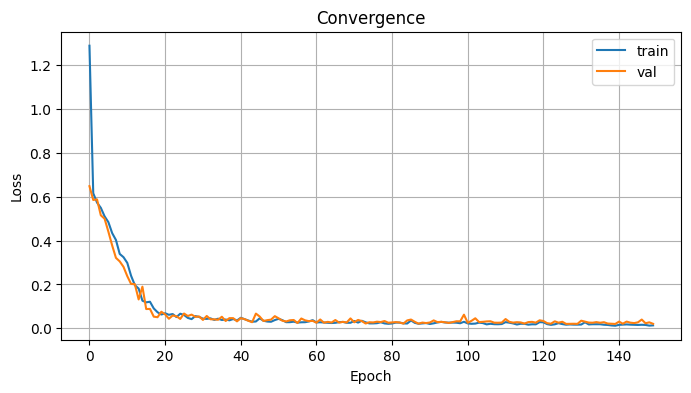

In [37]:
import matplotlib.pyplot as plt

train = np.array(history.get('train', []))
val = np.array(history.get('val', []))

plt.figure(figsize=(8,4))
if train.size:
    plt.plot(train, label='train')
if val.size:
    plt.plot(val, label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Convergence')
plt.legend()
plt.grid(True)
plt.show()

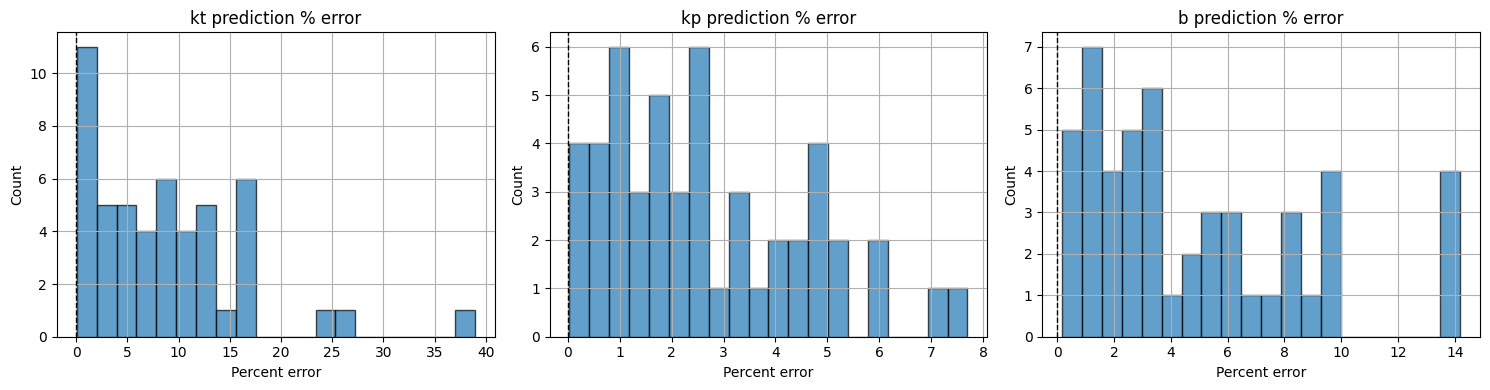

In [38]:
errors = results_df[['kt_pred', 'kp_pred', 'b_pred']].copy()
errors.columns = ['kt', 'kp', 'b']
actual = results_df[['kt', 'kp', 'b']]
errors = np.abs((errors - actual), dtype=float)/ actual * 100
errors = errors.rename(columns=lambda c: f'{c}_err_pct')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, param in zip(axes, ['kt', 'kp', 'b']):
    err_col = f'{param}_err_pct'
    ax.hist(errors[err_col], bins=20, alpha=0.7, color='C0', edgecolor='k')
    ax.axvline(0, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'{param} prediction % error')
    ax.set_xlabel('Percent error')
    ax.set_ylabel('Count')
    ax.grid(True)

plt.tight_layout()
plt.show()

In [39]:
print(errors.mean())
print(errors.std())
# print(train)
# print(val)

kt_err_pct    8.715276
kp_err_pct    2.646172
b_err_pct     4.831661
dtype: float64
kt_err_pct    7.769813
kp_err_pct    1.917483
b_err_pct     3.886121
dtype: float64


In [40]:
results_df.head()

,kt,kt_pred,kp,kp_pred,b,b_pred,vx,vy,phi
0,0.644187,0.894955,1.180286,1.206963,0.981994,1.008225,"[[[-0.0037319672, -0.005033593, -0.0054021594,...","[[[-0.0054650432, -0.005904598, -0.0061017275,...","[[[0.41543302, 0.43340534, 0.4150556, 0.358571..."
1,0.318581,0.263850,0.807613,0.838847,0.355086,0.405429,"[[[1.0860322e-05, 8.161221e-06, 4.677427e-06, ...","[[[-7.286926e-06, -8.316344e-06, -9.464944e-06...","[[[0.1916617, 0.19802135, 0.2054465, 0.2127434..."
2,0.233790,0.235628,0.848445,0.875085,0.518820,0.547183,"[[[1.3598887e-05, 2.5753157e-05, 3.6305566e-05...","[[[3.7301157e-05, 3.816645e-05, 3.9705734e-05,...","[[[0.20817557, 0.20133224, 0.19502234, 0.18952..."
3,0.066654,0.064420,1.021264,1.045292,0.733374,0.756655,"[[[2.787033e-05, 1.6882224e-05, 7.3107617e-06,...","[[[-3.50014e-05, -3.7956375e-05, -3.947387e-05...","[[[0.15909661, 0.12636667, 0.11069958, 0.11466..."
4,0.825779,0.700628,1.060659,1.106466,0.410351,0.448641,"[[[-2.1209894e-06, -4.590914e-06, -5.380395e-0...","[[[1.114034e-05, 8.10635e-06, 5.3976746e-06, 3...","[[[0.2089442, 0.20760983, 0.20503657, 0.201469..."
